<center><h1>Leonez_Teresa_HW6</h1></center>

Name: Teresa Leonez
<br>
Github Username: ttl229
<br>
USC ID: 9630346635

## 1. Tree-Based Methods

Import packages

In [30]:
# Import Standard Packages
import math
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Question 1 packages
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix, roc_auc_score, RocCurveDisplay, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from xgboost import XGBClassifier

In [81]:
# Helper Functions
def get_report(model, X, y): 
    predicted = model.predict(X)         # run model to predict y
    prob = model.predict_proba(X)[:, 1]  # probability
    mc_error = 1 - accuracy_score(y, predicted)
    auc_score = roc_auc_score(y, prob)
    matrix = confusion_matrix(y, predicted)
    print(f"MC error: {mc_error}, AUC: {auc_score},\n Matrix:\n {matrix}")
    RocCurveDisplay.from_predictions(y, prob); plt.show()
    return mc_error, auc_score, matrix

def get_coeff_var(s, m):
    cv = s/m
    return cv

def plot_points(X, y, title):
    fig, ax = plt.subplots(figsize=(5,5))
    ax.scatter(X[:,0], X[:,1], c=y, s=80, edgecolor='k')
    ax.set_xlim(0,5); ax.set_ylim(0,5); ax.set_aspect('equal')
    ax.set_xlabel('X1'); ax.set_ylabel('X2'); ax.set_title(title)
    for i, (x1, x2) in enumerate(X, start=1):  # label observations
        ax.annotate(str(i), (x1, x2), textcoords='offset points', xytext=(7, 7))
    return ax

def get_midpoint(a, b):
    # gets midpoint as an (x,y) point between two points a and b
    x, y = (X[a-1] + X[b-1]) / 2  # Convert numpy label to obs label 1-7
    return x, y

def get_hyperplane(pair1, pair2): # Takes two closest red-blue pair points to get line
    # gets midpoint between pair 1 and pair 2 points as (x,y) point
    x1, y1 = (X[pair1[0]-1] + X[pair1[1]-1]) / 2
    x2, y2 = (X[pair2[0]-1] + X[pair2[1]-1])/ 2
    slope = (y2 - y1) / (x2 - x1)
    intercept = y1 - slope * x1
    hyperplane_line = f"X2 = {slope:.2f}*X1 + {intercept:.2f}"
    print(hyperplane_line)
    return slope, intercept
    
def draw_line(ax, slope, intercept, **kw):
    xs = np.linspace(0, 5, 100)          
    ax.plot(xs, slope*xs + intercept, **kw)

### (a) Download the APS Failure data

In [5]:
# import data
train_filepath = "../data/aps_failure_training_set.csv"  # training data set
test_filepath  = "../data/aps_failure_test_set.csv"      # test data set
train_df = pd.read_csv(train_filepath, skiprows=20, na_values="na")
test_df  = pd.read_csv(test_filepath,  skiprows=20, na_values="na")
features, target = train_df.columns.drop("class"), "class"     # Split features and dependent class variable

### (b) Data Preparation

#### (i) Research what types of techniques are usually used

# Use Median Imputation to fill in empty values
Imputation techniques:
I decided to use median imputation as it's outlier resistant.

In [6]:
# Assign X,y train and test set
X_train = train_df[features]  
y_train = (train_df[target] == "pos").astype(int)
X_test  = test_df[features] 
y_test  = (test_df[target] == "pos").astype(int)
imp_train = SimpleImputer(strategy="median")   # imputing using median value
imp_test  = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imp_train.fit_transform(X_train), columns=X_train.columns)
X_test  = pd.DataFrame(imp_test.fit_transform(X_test),  columns=X_test.columns)

#### (ii) Calculate the coefficient of variation

In [7]:
sample_sd, sample_mean = X_train.std(), X_train.mean()
cv = get_coeff_var(sample_sd, sample_mean)
cv_sorted = cv.sort_values(ascending=False)
print(cv_sorted)

cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
             ...    
bo_000      0.792383
bp_000      0.753392
bq_000      0.718534
br_000      0.689112
cd_000      0.000000
Length: 170, dtype: float64


#### (iii) Plot a correlation matrix

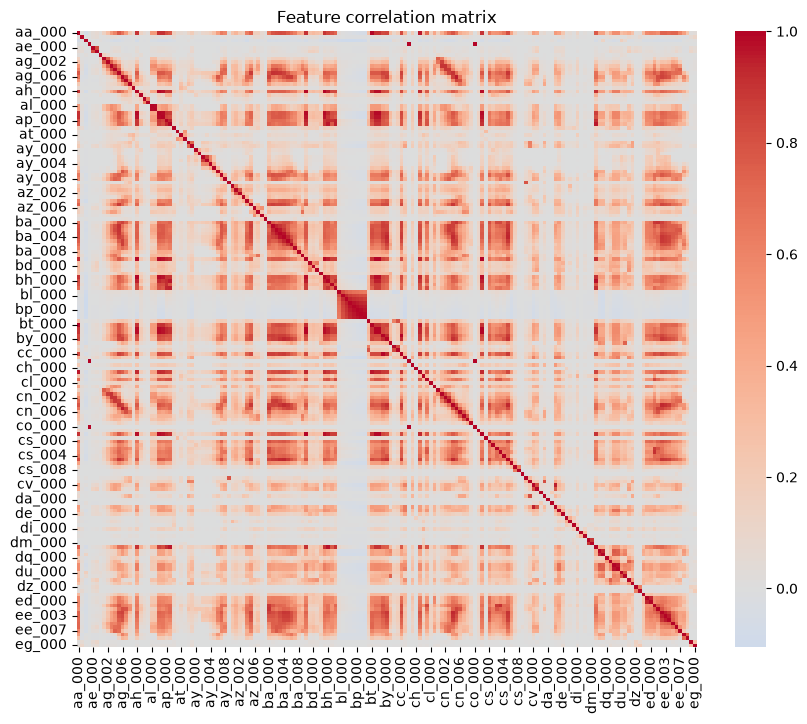

In [8]:
# Plot correlation matrix with all 170 features
plt.figure(figsize=(10, 8))
sns.heatmap(X_train.drop(columns="cd_000").corr(), cmap="coolwarm", center=0)
plt.title("Feature correlation matrix")
plt.show()

#### (iv) Make scatter plots and box plots

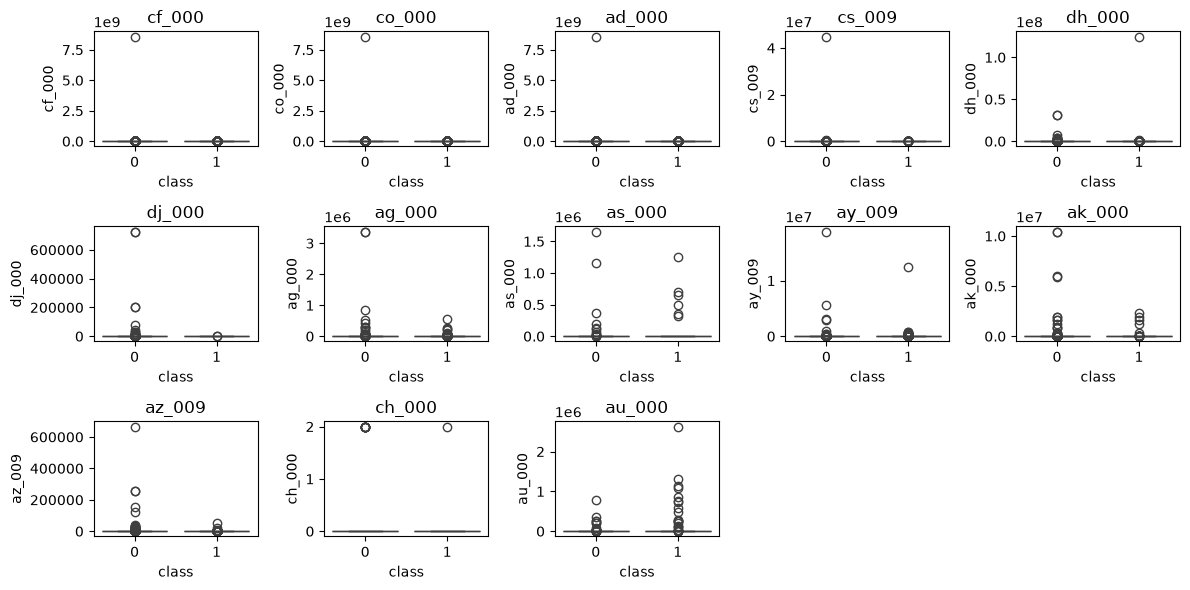

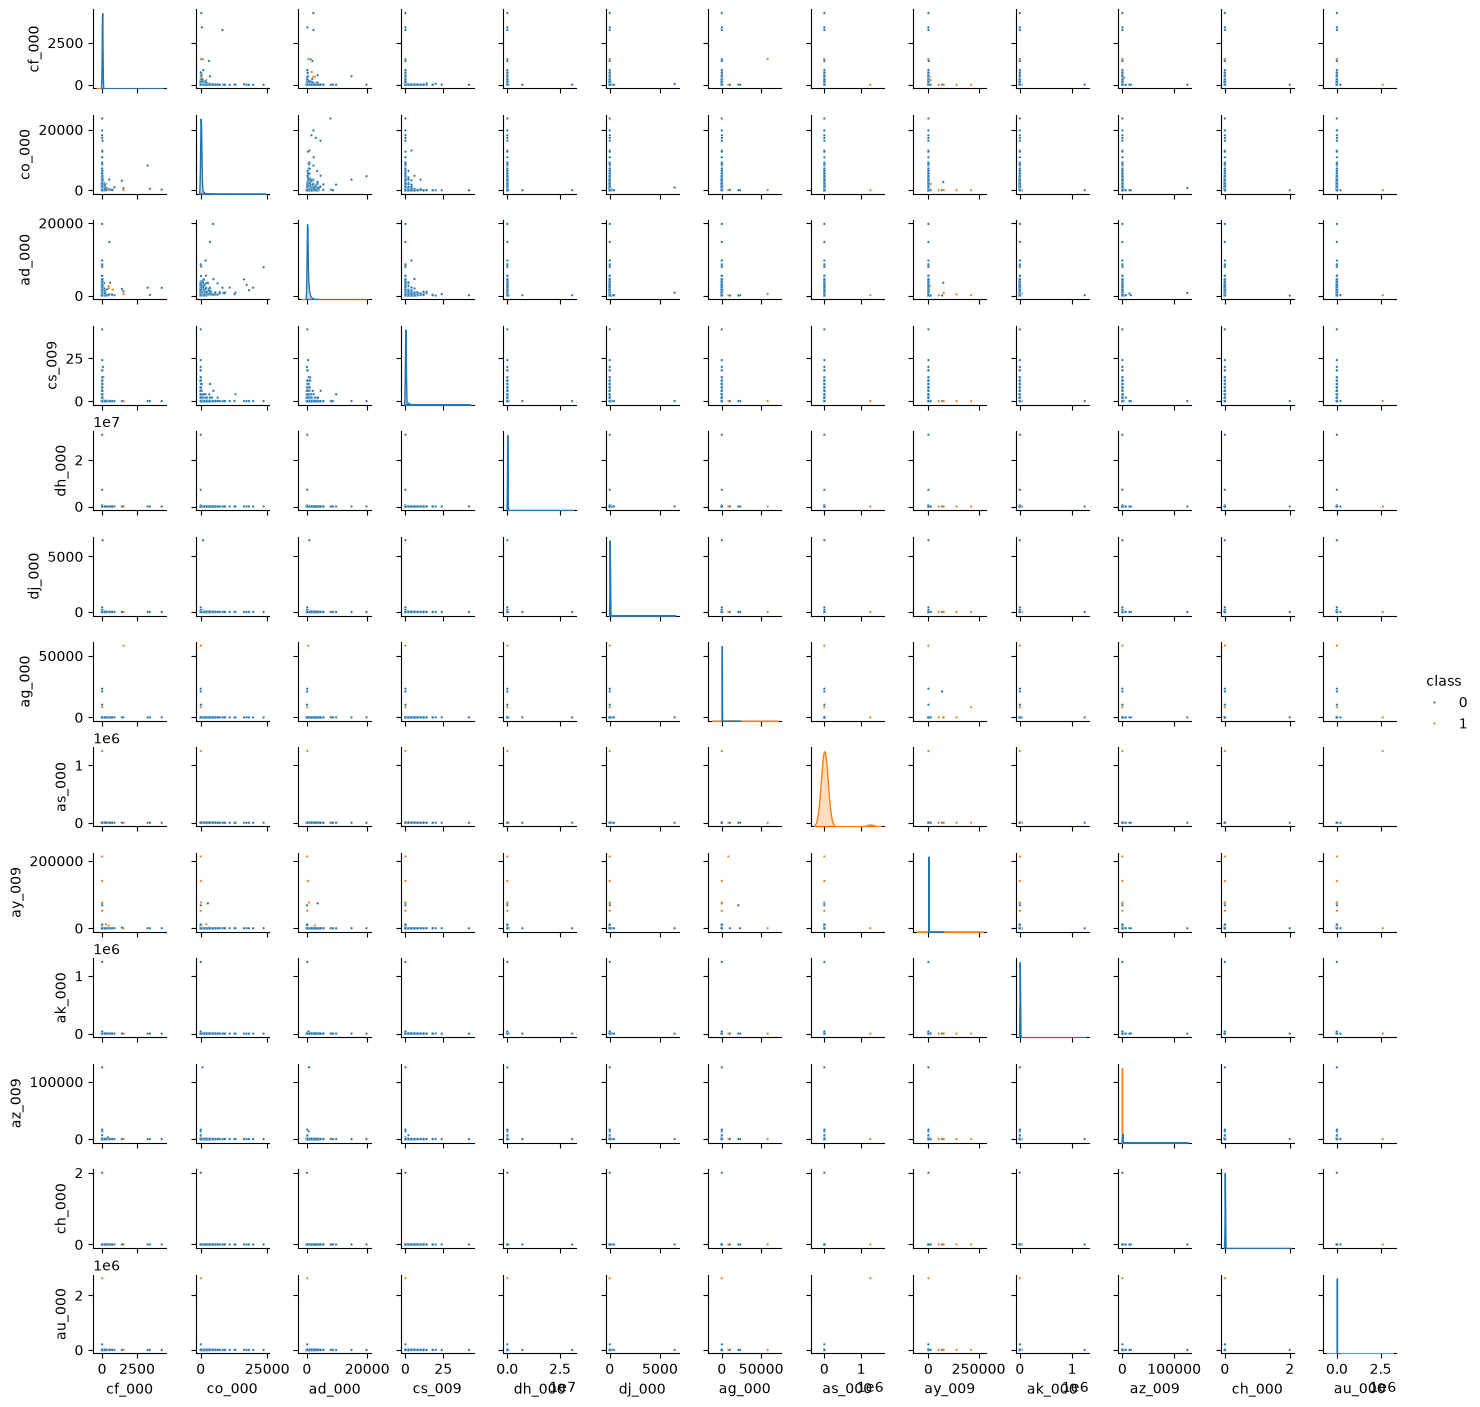

In [9]:
n = int(math.sqrt(170)) # get sqrt of 170, round to closest int
top_n_features = cv_sorted.iloc[0:n].index # get name of top n features
df_top = X_train[top_n_features].copy() # assign top √170 features to df
df_top["class"] = y_train.values

# Make Box Plot of all top √170 features
fig, axes = plt.subplots(3, 5, figsize=(12, 6))
for ax, feat in zip(axes.flat, top_n_features):
    sns.boxplot(data=df_top, x="class", y=feat, ax=ax)
    ax.set_title(feat)
for ax in axes.flat[len(top_n_features):]:   
    ax.axis("off")
plt.tight_layout(); plt.show()

# Show scatterplot of top features
sample = df_top.sample(3000, random_state=0)
sns.pairplot(sample, vars=top_n_features, hue="class", height=1.1, plot_kws={"s": 3})
plt.show()

The box and whisker plots show a very skewed data set. Since the dataset is missing so many values, the actual data (features with non-zero readings) are read as outliers. From the scatter plots, a few of the top 3 variables with highest coefficient variations (cf_000, co_000, ad_000) show higher sensor readings more likely to belong in the positive class than lower sensor readings, however the classes overlap in these cases. The rest of the variables do not show a visible difference.

#### (v) Is this data set imbalanced?

In [10]:
train_df["class"].value_counts()  # Get positive and negative class counts from entire dataset

class
neg    59000
pos     1000
Name: count, dtype: int64

This dataset is imbalanced, out of 60k cases, there are only 1000 positive counts. The target predicted class (positive) is rare, which results in less data available compared to the negative class.

### (c) Train a random forest

Random Forest Train Set
MC error: 0.0, AUC: 1.0,
 Matrix:
 [[59000     0]
 [    0  1000]]


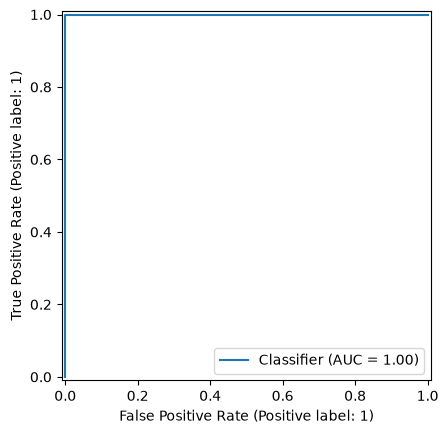

Random Forest Test Set
MC error: 0.007249999999999979, AUC: 0.9943556266666667,
 Matrix:
 [[15609    16]
 [  100   275]]


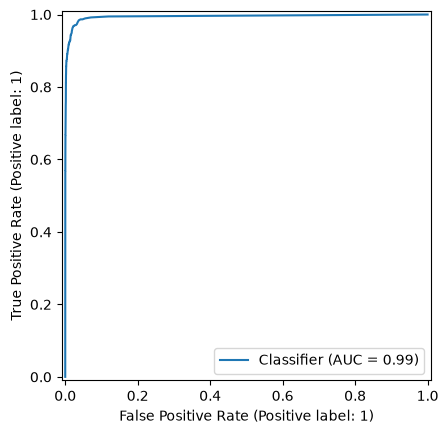

In [11]:
rf = RandomForestClassifier(n_estimators=200, oob_score=True, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)  # Fit the random forest model on training data
print("Random Forest Train Set")
mc_train, auc_train, train_matrix = get_report(rf, X_train, y_train) # Get report data for model on training data
print("Random Forest Test Set")
mc_test, auc_test, test_matrix = get_report(rf, X_test, y_test) # Get report data for test data

In [12]:
oob_error = 1-rf.oob_score_
print(f"OOB Error: {oob_error}") # Calculate OOB Error

OOB Error: 0.005833333333333357


The test set resulted in misclassification rate of 0.00725 (.73%), or 16 false positives (Type 1) and 100 false negatives (Type 2). The model caught 275 out of the total 375 actual cases of APS failure, and missed 100 actual cases.  The out of bag error was 58%, which was slightly better than the test error rate. While both error rates seem low, the model missed over a quarter (27%) of actual positives, since most cases were negative, indicating there is class imbalance.

### (d) Research class imbalance in random forest

Two common methods to address class imbalance in RF: First is using weighted classes (WRF), which is a cost-sensitive method penalizing misclassifications of imbalanced class (positive in this case). Second is ensemble down sampling (BRF), which randomly down-samples the majority class for every tree grown to match the minority class samples available.

/opt/miniconda3/lib/python3.13/site-packages/imblearn/ensemble/_forest.py:827: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


Balanced Random Forest Train:
MC error: 0.055916666666666615, AUC: 0.9975965169491525,
 Matrix:
 [[55645  3355]
 [    0  1000]]


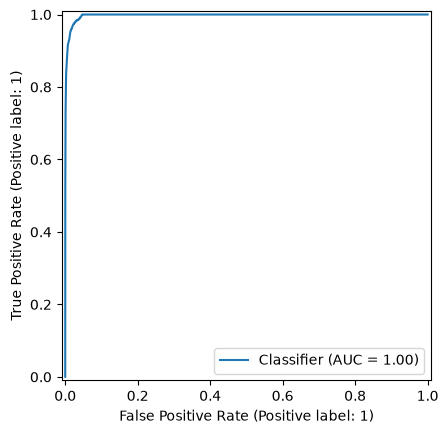

Balanced Random Forest Test:
MC error: 0.05312499999999998, AUC: 0.9924739413333332,
 Matrix:
 [[14781   844]
 [    6   369]]


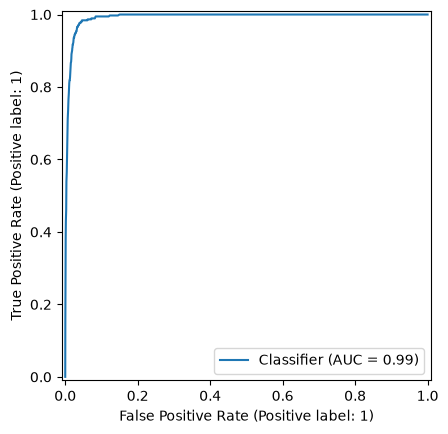

0.046050000000000035

In [19]:
brf = BalancedRandomForestClassifier(n_estimators=200, oob_score=True, n_jobs=-1,
                                     random_state=42, sampling_strategy="auto",
                                     replacement=False, bootstrap=True)  # alter bootstrapping method for each tree
brf.fit(X_train, y_train)  # Fit using the down-sampled model
print("Balanced Random Forest Train:")
mc_train_brf, auc_train_brf, train_matrix_brf = get_report(brf, X_train, y_train)
print("Balanced Random Forest Test:")
mc_test_brf,  auc_test_brf,  test_matrix_brf  = get_report(brf, X_test,  y_test)
oob_error_brf = 1-brf.oob_score_
oob_error_brf

After down-sampling to account for class imbalance in dataset, the model increased its recall and only misclassified 6 out of 375 actual positive cases (Type 2 error) compared to 100 in 1c. The tradeoff is the false positives (Type 1 error) cases went up to 5.4% (844/15625). The OOB error rate rose from .58% to 4.6%. In application, this model is more useful given that Type 2 errors are more costly in the real world.

### (e) XGBoost and Model Trees

Best alpha: 0.01
5-fold CV error: 0.62%
MC error: 0.0, AUC: 1.0,
 Matrix:
 [[59000     0]
 [    0  1000]]


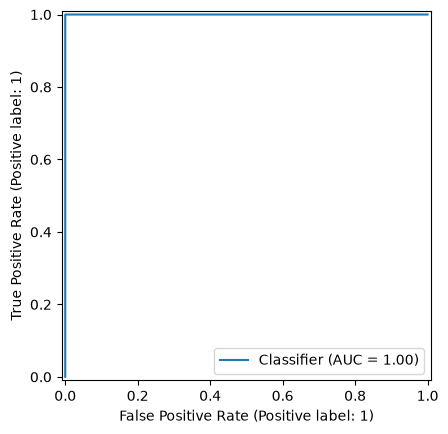

MC error: 0.00593750000000004, AUC: 0.9939182933333334,
 Matrix:
 [[15612    13]
 [   82   293]]


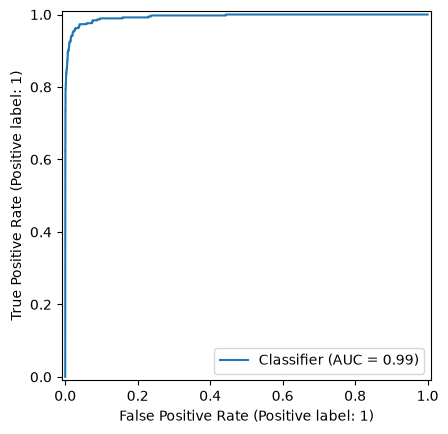

In [27]:
# Use 5 fold CV
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# Test alphas using 5 fold CV to get lowest CV error
xgb_grid = GridSearchCV(
    XGBClassifier(objective="binary:logistic", n_estimators=200, tree_method="hist",
                  n_jobs=-1, random_state=42, eval_metric="logloss"),
    param_grid={"reg_alpha": [0, 0.01, 0.1, 1, 10]},   # reg_alpha = L1 strength
    cv=kfold, scoring="accuracy")
xgb_grid.fit(X_train, y_train) # CV for each alpha, refit model with best 

xgb = xgb_grid.best_estimator_  # Best model trained with best alpha
print("Best alpha:", xgb_grid.best_params_["reg_alpha"])
print(f"5-fold CV error: {1 - xgb_grid.best_score_:.2%}")

# Report on train and test sets
mc_train_xgb, auc_train_xgb, train_matrix_xgb = get_report(xgb, X_train, y_train)
mc_test_xgb,  auc_test_xgb,  test_matrix_xgb  = get_report(xgb, X_test,  y_test)

The XGBoost model had a misclassification of .59% on the test set, resulting in 82 false negatives out of 375 actual positives, performing slightly better than the uncompensated random forest from 1c. The 5 fold CV error was .62%, which was only slightly higher than the test error by .03%, indicating a good estimate from the CV.

### (f) Use SMOTE to pre-process your data

Best alpha: 0.01
5-fold CV error: 0.60%
MC error: 0.0, AUC: 1.0,
 Matrix:
 [[59000     0]
 [    0  1000]]


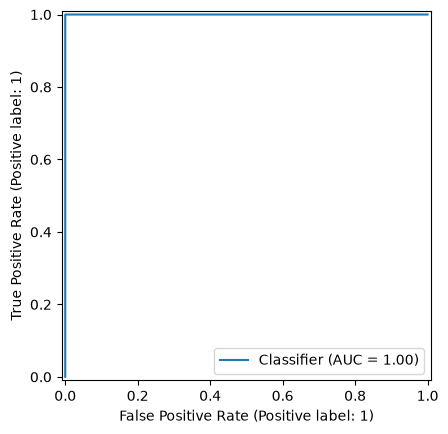

MC error: 0.007312500000000055, AUC: 0.9916055893333333,
 Matrix:
 [[15564    61]
 [   56   319]]


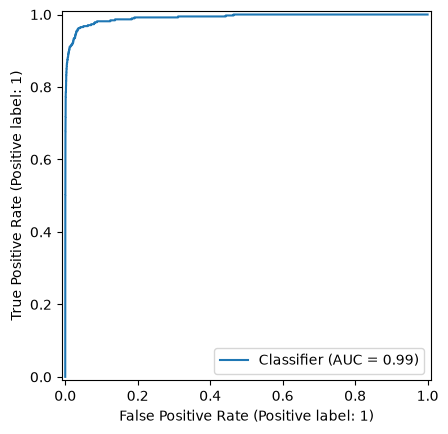

In [31]:
# Create SMOTE pipeline 
smote_pipeline = Pipeline([("smote", SMOTE(random_state=42)), ("xgb", XGBClassifier(objective="binary:logistic", n_estimators=200, tree_method="hist",
                          n_jobs=-1, random_state=42, eval_metric="logloss"))])
# SMOTE for each CV alpha, on training fold 
smote_grid = GridSearchCV(smote_pipeline,
    param_grid={"xgb__reg_alpha": [0, 0.01, 0.1, 1, 10]},    # Try alphas 
    cv=kfold, scoring="accuracy")  # Cross validate using 5-fold 
# SMOTE inside each training fold, CV each alpha, then fit model on full set
smote_grid.fit(X_train, y_train)  

Best alpha: 0.01
5 Fold CV Error: 0.60%
SMOTE Model Train Results:
MC error: 0.0, AUC: 1.0,
 Matrix:
 [[59000     0]
 [    0  1000]]


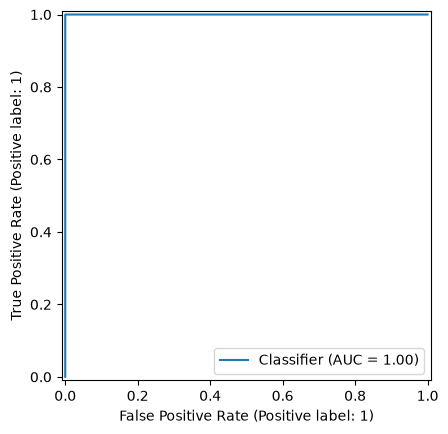

SMOTE Model Test Results:
MC error: 0.007312500000000055, AUC: 0.9916055893333333,
 Matrix:
 [[15564    61]
 [   56   319]]


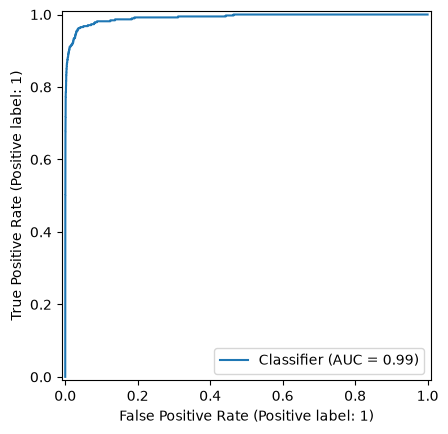

In [36]:
xgb_smote = smote_grid.best_estimator_  # Best model with best alpha
print("Best alpha:", smote_grid.best_params_["xgb__reg_alpha"])
print(f"5 Fold CV Error: {1 - smote_grid.best_score_:.2%}")
print("SMOTE Model Train Results:")
mc_train_sm, auc_train_sm, train_matrix_sm = get_report(xgb_smote, X_train, y_train)

# Run model on test set without SMOTE
print("SMOTE Model Test Results:")
mc_test_sm, auc_test_sm, test_matrix_sm = get_report(xgb_smote, X_test, y_test)

# Compare the uncompensated case with SMOTE case
Using the SMOTE technique to pre-process data in 5 fold CV gets best regularization alpha of .01. After fitting the model with best alpha on all the training data, the misclassification error is .73% with AUC .99. The total missed positives (Type 2 error) goes down nearly 50% from 100 to 56 out of 375 from the original uncompensated model. False positives (Type 1 error) increase from 16 to 60, but given the real world cost is much higher for missing actual positives than misidentifying negatives as positive, this results in a more useful model.

In [32]:
# Save trained model to file for faster reload
import joblib
joblib.dump(xgb_smote, "xgb_smote.pkl")

['xgb_smote.pkl']

## 2. ISLR 6.6.3

6.6.3.a. Answer: iv. As we increase s, the training error will continue to decrease, since increasing S allows keeping more variable coefficients, which can only improve the model. 
6.6.3.b. Answer: ii. As we increase s on the test data, we expect the error to decrease until a threshold, then increase into a U shape, as it approaches the irreducible error or noise of the real world, the model will overfit to the training data.
6.6.3.c. Answer: iii. As we increase s, the variance will increase, since increasing s makes the model more flexible, allowing for less bias when new data is introduced.
6.6.3.d. Answer: iv. The square bias will steadily decrease as we increase s, because the model is more flexible.
6.6.3.e. Answer: v. The irreducible error is a constant that represents the noise in the real world that cannot be addressed by adjusting s.

## 3. ISLR 6.6.5

6.6.5.a 
for simplicity, renaming x(1,1), x(1,2), x(2,1), x(2,2) to a,b,c,d, therefore:<br>
(y1-beta1*a - beta2*b)^2 + (y2-beta1*c - beta2*d)^2 + lambda(beta1^2 + beta2^2) <br>
since a = b and c = d, we can simplify to: <br>
(y1-beta1*a - beta2*a)^2 + (y2-beta1*c - beta2*c)^2 + lambda(beta1^2 + beta2^2)
>$\min_{\beta_1,\beta_2}\ (y_1-\beta_1 a-\beta_2 a)^2+(y_2-\beta_1 c-\beta_2 c)^2+\lambda(\beta_1^2+\beta_2^2)$

Since the data is centered, $y_1+y_2=0$ and $a+c=0$, so $y_2=-y_1$ and $c=-a$. This simplifies to:

>$= \big(y_1-a(\beta_1+\beta_2)\big)^2+\big(-y_1+a(\beta_1+\beta_2)\big)^2+\lambda(\beta_1^2+\beta_2^2)$

>$= 2\big(y_1-a(\beta_1+\beta_2)\big)^2+\lambda(\beta_1^2+\beta_2^2)$

>$= 2y_1^2-4ay_1(\beta_1+\beta_2)+2a^2(\beta_1+\beta_2)^2+\lambda(\beta_1^2+\beta_2^2)$

6.6.5.b. Since the data is centered with identical features, the prediction model only depends on the sum of the coefficents. For any fixed sum t, the ridge penalty (beta1^2 + beta2^2) is smallest when beta1 = beta2 = t/2. (example: if beta1 + beta2 = 4, then best choice for beta1 and beta2 will be 2.

>$\beta_1 a+\beta_2 a=a(\beta_1+\beta_2)$

6.6.5.c. Lasso Optimization Formula

>$\min_{\beta}\ \sum_{i=1}^{n}\Big(y_i-\beta_0-\sum_{j=1}^{p}\beta_j x_{ij}\Big)^2+\lambda\sum_{j=1}^{p}|\beta_j|$

>$\min_{\beta_1,\beta_2}\ (y_1-\beta_1 a-\beta_2 a)^2+(y_2-\beta_1 c-\beta_2 c)^2+\lambda(|\beta_1|+|\beta_2|)$

>$= 2\big(y_1-a(\beta_1+\beta_2)\big)^2+\lambda(|\beta_1|+|\beta_2|)$

>$= 2y_1^2-4ay_1(\beta_1+\beta_2)+2a^2(\beta_1+\beta_2)^2+\lambda(|\beta_1|+|\beta_2|)$

6.6.5.d. When we switch from ridge to lasso, the penalty always results in the same regardless of the beta1 and beta2 values, since adding the sum of absolute values of the 2 coefficients will result in the same penalty no matter what the we use. (If beta1 + beta2 = t, any positive non-zero t gives us the same RSS and the same peanlty lambda * |t|).

## 4. ISLR 8.4.5

In [52]:
prob_set = np.array([0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75])
counts = len(prob_set)  # Total number of observations

# Using majority vote method, classify instance as red when p > .5
class_red = prob_set > 0.5
total_red = class_red.sum()
prob_red = total_red/counts
print(f"Method 1: \nUsing majority method, {total_red} out of {counts} observations classify as red. \nSince p of red = {prob_red} and {prob_red} > .5, then X will classify as red.") 

# Using average prob method
mu = prob_set.mean()  # Get the average of all observations p / total count
average_class =  'red' if mu > 0.5 else 'green' # Classify as red only if mu is greater than .5
print(f"Method 2: \nThe average of the probability set is .45 (sum / 10), \nand since .45 is < .5, X will classify as green.")

Method 1: 
Using majority method, 6 out of 10 observations classify as red. 
Since p of red = 0.6 and 0.6 > .5, then X will classify as red.
Method 2: 
The average of the probability set is .45 (sum / 10), 
and since .45 is < .5, X will classify as green.


## 5. ISLR 9.7.3

<Axes: title={'center': "Observations (n=7, p=2 'red' or 'blue')"}, xlabel='X1', ylabel='X2'>

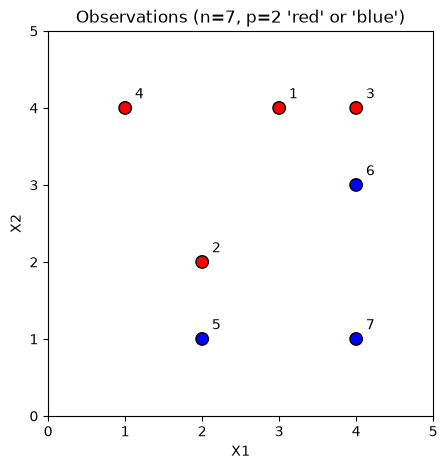

In [83]:
# 9.7.3.a.
X = np.array([[3,4],[2,2],[4,4],[1,4],[2,1],[4,3],[4,1]])
y = np.array(['red','red','red','red','blue','blue','blue'])
plot_points(X, y, "Observations (n=7, p=2 'red' or 'blue')")

Shortest distance between classes:
D(Obs2, Obs5) = 1.0
 and D(Obs3, Obs 6) = 1.0
X2 = 1.00*X1 + -0.50


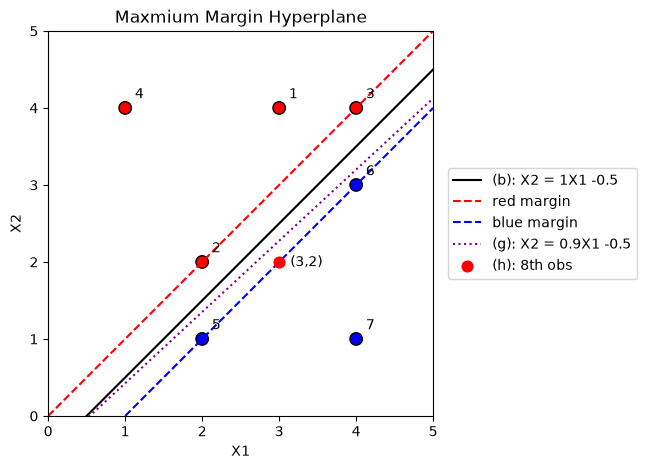

In [109]:
# 9.7.3.b.
# Get closest distance between pos class (red) and neg class (blue)
# d_best = min value of √[(x1red - x1blue)^2 + (x2red - x2blue)^2]
d_best_1 = np.linalg.norm(X[1]-X[4]) # Obs 2 and obs 5 
d_best_2 = np.linalg.norm(X[2]-X[5]) # Obs 3 and Obs 6
print(f"Shortest distance between classes:\nD(Obs2, Obs5) = {d_best_1}\n and D(Obs3, Obs 6) = {d_best_2}")

# Get hyperplane line between red-blue classes
pair1 = (2, 5)  # Obs 2-5
pair2 = (3, 6)  # Obs 3-6
slope, intercept = get_hyperplane(pair1, pair2)

# Plot answers for a-h on one graph
ax = plot_points(X, y, 'Maxmium Margin Hyperplane')
# Show maximum margin hyperplane line
draw_line(ax, slope, intercept, color='k', label=f'(b): X2 = {slope:.0f}X1 {intercept:+.1f}')
# Show margin using two dotted lines
ax.axline(X[1], X[2], color='red',  linestyle='--', label='red margin')    # obs 2 & 3
ax.axline(X[4], X[5], color='blue', linestyle='--', label='blue margin')   # obs 5 & 6
# Show not optimal hyperplane
bad_slope = slope-.075
draw_line(ax, bad_slope, intercept, color='purple', linestyle=':', label=f'(g): X2 = {bad_slope:.1f}X1 {intercept:+.1f}')
# For h. plot an observation so the two classes are no longer separated by hyperplane
ax.scatter(3, 2, color='red', s=60, zorder=3, label='(h): 8th obs')  
ax.annotate('(3,2)', (3, 2), textcoords='offset points', xytext=(8, -3)) # label 
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))
plt.show()

#9.7.3.b Answer: Hyperplane line simplifies to X2 = X1 -.5. (see plot above) 
#9.7.3.c.
X2 -X1 +.5 = 0 
#9.7.3.d. Answer: the margin is the distance between the red and blue dotted line to the center hyperplane = 0.5/√2 or approx .35 (d = |beta1x1 + beta2x2| / √(beta1^2 + beta2^2)
#9.7.3.e. Answer: The support vectors are observation points 2 (red), 5 (blue), 3 (red), and 6 (blue), the points directly on the dotted lines on the graph.
#9.7.3.f. Answer: Since observation 7 sits well outside the hyperplane towards blue, moving it slightly would not change the two closest red-blue pairs, and therefore the maximum margin classifier remains the same.
#9.7.3.g Answer: See the purple line in graph. By altering the slope, the hyperplane no longer maximizes the margin between red-blue pairs equally, although it still splits the classes without overlap, therefore qualifies as a hyperplane, while not being the optimal choice.

AI Use note: I used Claude to help simplify the markdown cells to latex format for visualization.